## Simple Harmonic Oscillator

### Discretizing the Euclidean Action
The exact Euclidean (imaginary time) action for the 1D Simple Harmonic Oscillator is:

$$S[x(\tau)] = \int_{\tau_a}^{\tau_b} d\tau \left( \frac{1}{2}m\dot{x}^2 + \frac{1}{2}m\omega^2x^2 \right)$$

The quantum mechanical transition amplitude (or partition function $Z$) between fixed endpoints $x(\tau_a) = x_a$ and $x(\tau_b) = x_b$ is given by the Feynman path integral over all possible trajectories $x(\tau)$:

$$Z = \int_{x(\tau_a)=x_a}^{x(\tau_b)=x_b} \mathcal{D}x(\tau)\, \exp\left( -\frac{S[x(\tau)]}{\hbar} \right)$$

To evaluate this via Monte Carlo, we discretize the time interval into $N$ slices of width $\varepsilon$ (where $N\varepsilon = \tau_b - \tau_a$). Replacing the derivative with a finite difference and the position with a slice average yields the discrete action:

$$\frac{S}{\hbar} = \frac{m\varepsilon}{2\hbar} \sum_{j=0}^{N-1} \left[ \left(\frac{x_{j+1} - x_j}{\varepsilon}\right)^2 + \omega^2 \left(\frac{x_{j+1} + x_j}{2}\right)^2 \right]$$


### Non-dimensionalization
To optimize the computation, we absorb all physical constants ($m, \hbar, \omega, \varepsilon$) into dimensionless variables. By defining $\kappa = \frac{1}{4}\varepsilon^2\omega^2$, a dimensionless position $d_k = x_k \sqrt{m / (\varepsilon\hbar)}$, and finally a rescaled position $u_j = d_j\sqrt{1+\kappa}$, the action simplifies to:

$$\frac{S}{\hbar} = \left[ \sum_{j=1}^{N-1} u_j^2 \right] - g \left[ \sum_{j=0}^{N-1} u_j u_{j+1} \right]$$

where $g = \frac{1 - \kappa}{1 + \kappa}$. 
* **Boundary Conditions:** The endpoints of the path are fixed at zero ($x_a = x_b = 0$), meaning $u_0 = u_N = 0$.
* **The Markov State:** A single state in our Markov chain is an entire particle path, represented by the $(N_t-1)$-dimensional vector $\mathbf{u} = (u_1, u_2, \dots, u_{N-1})$.

### Quantum Expectation Values via MCMC

*(Note: To avoid confusion with the number of Monte Carlo measurements $N_{\text{mc}}$, the number of discrete time slices is denoted as $N_t$.)*

To compute the expectation value of any physical observable $\mathcal{O}(\mathbf{u})$—such as the two-point propagator $\mathcal{O}(\mathbf{u}) = u(\tau_0 + \tau)u(\tau_0)$, we evaluate the ratio of two $(N_t - 1)$-dimensional integrals:

$$\langle \mathcal{O} \rangle = \frac{\displaystyle \int_{-\infty}^{\infty} du_1 \cdots du_{N_t-1} \; \mathcal{O}(\mathbf{u}) \, \exp\left( -\sum_{j=1}^{N_t-1} u_j^2 + g \sum_{j=0}^{N_t-1} u_j u_{j+1} \right)}{\displaystyle \int_{-\infty}^{\infty} du_1 \cdots du_{N_t-1} \; \exp\left( -\sum_{j=1}^{N_t-1} u_j^2 + g \sum_{j=0}^{N_t-1} u_j u_{j+1} \right)}$$

Instead of integrating over $N_t - 1 = 999$ dimensions on a grid, the Metropolis algorithm treats the normalized Boltzmann weight

$$w(\mathbf{u}) = \frac{e^{-S[\mathbf{u}]/\hbar}}{\int d^{N_t-1}u \, e^{-S[\mathbf{u}]/\hbar}}$$

as the target probability density. By sampling $N_{\text{mc}}$ decorrelated path configurations $\mathbf{u}^{(1)}, \mathbf{u}^{(2)}, \dots, \mathbf{u}^{(N_{\text{mc}})}$ according to $w(\mathbf{u})$, the path integral simplifies to a direct ensemble average:

$$\langle \mathcal{O} \rangle \approx \frac{1}{N_{\text{mc}}} \sum_{m=1}^{N_{\text{mc}}} \mathcal{O}\big(\mathbf{u}^{(m)}\big)$$

### The Local Update Strategy
If an auxiliary proposal density attempts to change all $N_t-1$ components of the path $\mathbf{u}$ simultaneously, the resulting change in the action ($\Delta S$) will be too large, driving the Metropolis acceptance probability to near zero. 

To achieve a reasonable acceptance rate ($\sim 50\%$), we perform **local updates**:
1. Randomly select a single time slice $j$.
2. Propose a small change to *only* $u_j$, holding all other points fixed.
3. Accept or reject this local change using the Metropolis algorithm. 

Because each time slice is assigned an equal probability of being selected, detailed balance is preserved and the chain ergodically covers the entire integration hypervolume.


#### Local Path Update Algorithm ($\mathbf{u} \to \mathbf{u}^{\text{new}}$)
Because changing a single time slice $u_j \to \tilde{u}_j = u_j + \delta$ only affects terms in the action involving $u_j$ and its nearest neighbors $u_{j-1}, u_{j+1}$, the change in action $\delta S = S[\tilde{\mathbf{u}}] - S[\mathbf{u}]$ can be computed locally in $\mathcal{O}(1)$ time.

The full dimensionless action over all $N_t$ time slices is:

$$\frac{S}{\hbar} = \left[ \sum_{k=1}^{N_t-1} u_k^2 \right] - g \left[ \sum_{k=0}^{N_t-1} u_k u_{k+1} \right]$$

When we perform a local update at a single time slice $u_j \to \tilde{u}_j = u_j + \delta$ (while keeping all other slices fixed), almost all terms in the sums cancel out in $\delta S = S[\tilde{\mathbf{u}}] - S[\mathbf{u}]$.

* **Why both $u_{j-1}$ and $u_{j+1}$ appear:** Expanding the nearest-neighbor sum $\sum_{k=0}^{N_t-1} u_k u_{k+1}$ around slice $j$ shows that $u_j$ participates in **two** adjacent links—the link from $j-1$ to $j$ (when $k = j-1$) and the link from $j$ to $j+1$ (when $k = j$):

$$\sum_{k=0}^{N-1} u_k u_{k+1} = \dots + \underbrace{u_{j-1} u_j}_{k = j-1} + \underbrace{u_j u_{j+1}}_{k = j} + \dots = \dots + u_j(u_{j-1} + u_{j+1}) + \dots$$

* **Local Action $S_{\text{local}}(u_j)$:** Collecting the only terms in $S/\hbar$ that depend on $u_j$ (its self-term and its interactions with its two immediate neighbors $j-1$ and $j+1$) gives:

$$\frac{S_{\text{local}}(u_j)}{\hbar} = u_j^2 - g\, u_j(u_{j-1} + u_{j+1})$$

* **Subtracting Old from New ($\tilde{u}_j = u_j + \delta$):**

$$\frac{\delta S}{\hbar} = \frac{S_{\text{local}}(u_j + \delta) - S_{\text{local}}(u_j)}{\hbar} = \Big[(u_j + \delta)^2 - u_j^2\Big] - g\Big[(u_j + \delta) - u_j\Big](u_{j-1} + u_{j+1})$$

$$\frac{\delta S}{\hbar} = (2u_j\delta + \delta^2) - g\delta(u_{j-1} + u_{j+1}) = \delta\Big(\delta + 2u_j - g(u_{j-1} + u_{j+1})\Big)$$

**Single Sweep Procedure:**
1. **Select Slice:** Randomly choose an interior time-slice index $j \in \{1, 2, \dots, N_t - 1\}$ with equal probability.
2. **Propose Shift:** Draw a uniform random shift $\delta \in [-\Delta, \Delta]$ and propose $\tilde{u}_j = u_j + \delta$.
3. **Compute Local $\delta S$:** Evaluate $\delta S / \hbar = \delta(\delta + 2u_j - g(u_{j-1} + u_{j+1}))$.
4. **Accept/Reject:** Since the uniform proposal is symmetric ($R(\tilde{u}_j \leftarrow u_j) = R(u_j \leftarrow \tilde{u}_j)$), accept $u_j^{\text{new}} = \tilde{u}_j$ with probability:
   $$P_{\text{acc}} = \min\left(1, e^{-\delta S / \hbar}\right)$$
   If rejected, retain the old value $u_j^{\text{new}} = u_j$.
5. **Complete Sweep:** Repeat steps (1)–(4) $N_t$ times to constitute **one updating sweep** across the path.


#### Initialization, Thermalization, and Tuning Parameters
* **Initial Configuration:**
  * **Cold Start:** Set $u_j = 0$ for all $j$ (completely ordered, ground-like path).
  * **Hot Start:** Set $u_j$ to random values for all $j$ (disordered, high-action path).
* **Thermalization ($N_{\text{therm}}$):** Evolve the path for $N_{\text{therm}}$ sweeps while monitoring simple observables until the chain reaches equilibrium (its stationary fixed point) before taking measurements.
* **The Four Simulation Parameters:**
  1. **$\varepsilon$ (Lattice Spacing):** Chosen small enough that discretization errors are negligible (e.g., $\omega\varepsilon = 0.25$, $N_t = 1000$).
  2. **$\Delta$ (Proposal Width):** Tuned to achieve an acceptance rate around $50\%\text{--}60\%$ (e.g., $\Delta = 1.5$ for $\omega\varepsilon = 0.25$).
  3. **$N_{\text{sweeps}}$ (Skip Between Measurements):** Number of sweeps skipped between successive measurements to reduce autocorrelations (e.g., monitoring the two-point correlator $\langle u(\tau_0 + 5)u(\tau_0)\rangle$ shows $\sim 100$ sweeps reduces autocorrelation to $\approx 0.1$).
  4. **$N_{\text{mc}}$ (Total Measurements):** Chosen large enough to achieve the desired statistical precision.

### Glossary of the Four "$N$" Parameters in Path Integral MCMC

| Symbol | Name | Meaning in the Simulation | Typical Value |
| :--- | :--- | :--- | :--- |
| **$N_t$** | **Number of Time Slices** | How many discrete points make up **one single path** $\mathbf{u} = (u_1, \dots, u_{N_t-1})$. Updating $N_t$ random points equals **1 sweep**. | $1000$ |
| **$N_{\text{therm}}$** | **Thermalization Sweeps** | Number of initial "warm-up" sweeps discarded at the start of the run so the path forgets its artificial initial state (hot/cold start) and reaches equilibrium. | $200\text{--}1000$ |
| **$N_{\text{sweeps}}$** | **Sweeps Between Measurements** | Number of sweeps skipped *between* saved measurements so successive paths are decorrelated (low autocorrelation). | $20\text{--}100$ |
| **$N_{\text{mc}}$** | **Number of Measurements** | Total number of decorrelated path configurations saved and averaged over to compute $\langle O \rangle \pm \sigma / \sqrt{N_{\text{mc}}}$. | $10^3\text{--}10^5$ |

### Sequential vs. Random Sweeps & Two-Point Correlation Functions

#### Sequential Sweeps vs. Random Sweeps
* **Random Sweeps:** Choosing time slices $j \in \{1, \dots, N_t - 1\}$ at random with equal probability preserves **detailed balance** at every single local update (with identical transition matrix $\mathbf{P}$), but requires $N_t$ extra random number calls per sweep.
* **Sequential Sweeps:** Sweeping through the lattice in order ($j = 1, 2, \dots, N_t - 1$) requires fewer random number calls and is computationally faster.
  * **Loss of Detailed Balance, Preservation of Fixed Point:** Sequential updating violates detailed balance because forward sweeps ($1 \to N_t-1$) and reverse sweeps ($N_t-1 \to 1$) do not occur with equal probability. However, because each individual slice update matrix $\mathbf{P}_j$ leaves the target distribution $\mathbf{w}$ invariant ($\mathbf{w}^T \mathbf{P}_j = \mathbf{w}^T$), the product matrix for a full sweep $\mathbf{P}_{\text{sweep}} = \mathbf{P}_1 \mathbf{P}_2 \cdots \mathbf{P}_{N_t-1}$ still satisfies the **fixed-point condition**:
    $$\mathbf{w}^T \mathbf{P}_{\text{sweep}} = (\mathbf{w}^T \mathbf{P}_1)\mathbf{P}_2 \cdots \mathbf{P}_{N_t-1} = \mathbf{w}^T$$
  * Furthermore, because $\mathbf{P}_{\text{sweep}}$ is identical from sweep to sweep, all Markov chain limit theorems apply at the sweep level, and sequential sweeps slightly improve (reduce) autocorrelations compared to random sweeps (Fig. 8, right).


#### Two-Point Correlation Function $\langle u(\tau_0 + \tau) u(\tau_0) \rangle$ (Figs. 8–10)
To study physical correlations and monitor autocorrelation in the Simple Harmonic Oscillator ($\omega\varepsilon = 0.25$, $N_t = 1000$, $\Delta = 1.5$), we measure the **two-point correlation function** (propagator):

$$C(\tau) = \langle u(\tau_0 + \tau)\, u(\tau_0) \rangle$$

where $\tau_0$ is chosen in the bulk interior region of the path (far from the fixed boundaries $u_0 = u_{N_t} = 0$) and averaged over multiple interior $\tau_0$ slices to improve statistics.

* **Exact Analytical Result on the Lattice (for $N_t \gg 1$):**
  For the Gaussian action $\frac{S}{\hbar} = \sum u_j^2 - g \sum u_j u_{j+1}$ with $\sqrt{\kappa} = \frac{1}{2}\omega\varepsilon$ and $g = \frac{1-\kappa}{1+\kappa}$, inverting the tridiagonal quadratic form yields the exact discrete propagator as a function of integer slice separation $n = \tau / \varepsilon$:

$$ \langle u(\tau_0 + n\varepsilon)\, u(\tau_0) \rangle_{\text{exact}} = \frac{1 + \kappa}{4\sqrt{\kappa}} \left( \frac{1 - \sqrt{\kappa}}{1 + \sqrt{\kappa}} \right)^n$$

  For $\omega\varepsilon = 0.25$ ($\sqrt{\kappa} = 0.125$, $\kappa = 0.015625$), this gives $\langle u(\tau_0)^2 \rangle = 2.03125$ at $\tau/\varepsilon = 0$ or $n = 0$ and decays exponentially as $(7/9)^{\tau/\varepsilon} \approx e^{-\omega\tau}$ (allowing extraction of the energy gap $\hbar\omega$).

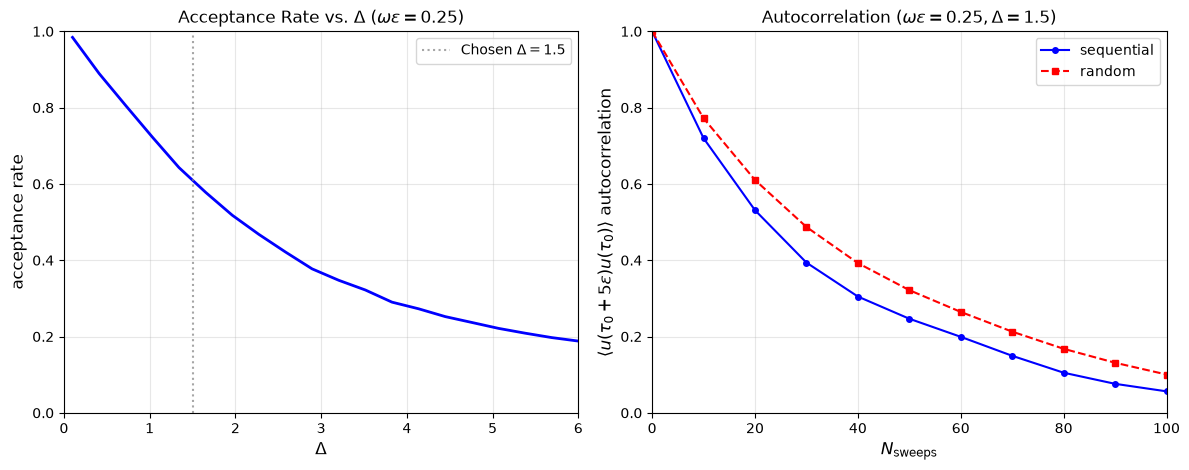

In [ ]:
# Autocorrelation and acceptance rate analysis for the SHO lattice example from the article. More details in my handwritten notes.

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(1)

# =====================================================================
# 1. SHO Lattice Parameters (Article Section 4)
# =====================================================================
omega_eps = 0.25
kappa = 0.25 * (omega_eps ** 2)
g = (1.0 - kappa) / (1.0 + kappa)
Nt = 1000  # Path has slices j = 0, 1, ..., Nt with u_0 = u_Nt = 0

# =====================================================================
# 2. Sequential and Random Sweep Functions
# =====================================================================
from numba import njit

@njit
def sweep_sequential(u, g, Delta, rng):
    Nt = len(u) - 1
    accepted = 0
    
    # Numba will execute this loop at C-speed
    for j in range(1, Nt):
        d = rng.uniform(-Delta, Delta)
        dS = d * (d + 2.0 * u[j] - g * (u[j - 1] + u[j + 1]))
        if dS <= 0.0 or rng.random() < np.exp(-dS):
            u[j] += d
            accepted += 1
            
    return accepted / (Nt - 1)

@njit
def sweep_random(u, g, Delta, rng):
    Nt = len(u) - 1
    accepted = 0
    
    for _ in range(Nt):
        j = rng.integers(1, Nt)
        d = rng.uniform(-Delta, Delta)
        dS = d * (d + 2.0 * u[j] - g * (u[j - 1] + u[j + 1]))
        if dS <= 0.0 or rng.random() < np.exp(-dS):
            u[j] += d
            accepted += 1
            
    return accepted / Nt

def measure_correlator(u, tau, i_start=200, i_end=800): # i_start and i_end define the middle region of the path to avoid boundary effects
    """Measures <u(tau0 + tau) u(tau0)> averaged over the middle region."""
    return np.mean(u[i_start : i_end] * u[i_start + tau : i_end + tau])

def compute_autocorr(series, max_lag=100):
    """Computes normalized autocorrelation rho(tau) for lags 0..max_lag."""
    fluct = series - np.mean(series)
    R0 = np.mean(fluct**2)
    N = len(series)
    rho = np.ones(max_lag + 1)
    for h in range(1, max_lag + 1):
        rho[h] = np.sum(fluct[:-h] * fluct[h:]) / ((N - h) *  R0)
    return rho

# =====================================================================
# 3. Left Plot of Fig. 8: Acceptance Rate vs. Delta
# =====================================================================
delta_grid = np.linspace(0.1, 6.0, 20)
acc_rates = []

for d_val in delta_grid:
    u_temp = np.zeros(Nt + 1)
    # Quick thermalization + measurement of acceptance rate
    for _ in range(30):
        sweep_sequential(u_temp, g, d_val, rng)
    acc = np.mean([sweep_sequential(u_temp, g, d_val, rng) for _ in range(20)])
    acc_rates.append(acc)

# =====================================================================
# 4. Right Plot of Fig. 8: Autocorrelation (Sequential vs. Random)
# =====================================================================
Delta = 1.5
n_therm = 300
n_track = 25000  # Consecutive sweeps to measure autocorrelation up to lag 25000 or number of paths 25000.
# A) Sequential sweeps
u_seq = np.zeros(Nt + 1)
for _ in range(n_therm):
    sweep_sequential(u_seq, g, Delta, rng) # thermalization sweeps
obs_seq = np.array([
    (sweep_sequential(u_seq, g, Delta, rng), measure_correlator(u_seq, tau=5))[1] # find a paths in equilibrium, then measure the correlator at tau=5. 
    for _ in range(n_track) # (func1(), func2())[1] syntax is used. The [1] returns the func2() only
]) # Repeat n_track times or for 25000 paths to get a long time series of the correlator at lag tau=5.

# B) Random sweeps
u_rand = np.zeros(Nt + 1)
for _ in range(n_therm):
    sweep_random(u_rand, g, Delta, rng) # thermalization sweeps
obs_rand = np.array([
    (sweep_random(u_rand, g, Delta, rng), measure_correlator(u_rand, tau=5))[1] # find a path u_rand in equilibrium, then measure the correlator at tau=5.
    for _ in range(n_track) 
]) # Repeat n_track times or for 25000 paths to get a long time series of the correlator at lag tau=5.

sweeps = np.arange(0, 101, 10)
rho_seq = compute_autocorr(obs_seq, max_lag=100)[sweeps] # NumPy Fancy Indexing (array indexing). Extracts data at sweeps = 0, 10, 20, ..., 100
rho_rand = compute_autocorr(obs_rand, max_lag=100)[sweeps] # Autocorrelation calculated for 25000 paths. 

# =====================================================================
# 5. Plot Reproduction of Fig. 8
# =====================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))

# Left Panel: Acceptance Rate vs Delta
ax1.plot(delta_grid, acc_rates, 'b-', lw=2)
ax1.axvline(1.5, color='gray', ls=':', alpha=0.7, label=r'Chosen $\Delta = 1.5$')
ax1.set_xlim(0, 6)
ax1.set_ylim(0, 1.0)
ax1.set_xlabel(r'$\Delta$', fontsize=12)
ax1.set_ylabel('acceptance rate', fontsize=12)
ax1.set_title(r'Acceptance Rate vs. $\Delta$ ($\omega\varepsilon = 0.25$)')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Right Panel: Autocorrelation vs N_sweeps
ax2.plot(sweeps, rho_seq, 'b-o', markersize=4, label='sequential')
ax2.plot(sweeps, rho_rand, 'r--s', markersize=4, label='random')
ax2.set_xlim(0, 100)
ax2.set_ylim(0, 1.0)
ax2.set_xlabel(r'$N_{\mathrm{sweeps}}$', fontsize=12)
ax2.set_ylabel(r'$\langle u(\tau_0+5\epsilon)u(\tau_0)\rangle$ autocorrelation', fontsize=12)
ax2.set_title(r'Autocorrelation ($\omega\varepsilon = 0.25, \Delta = 1.5$)')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

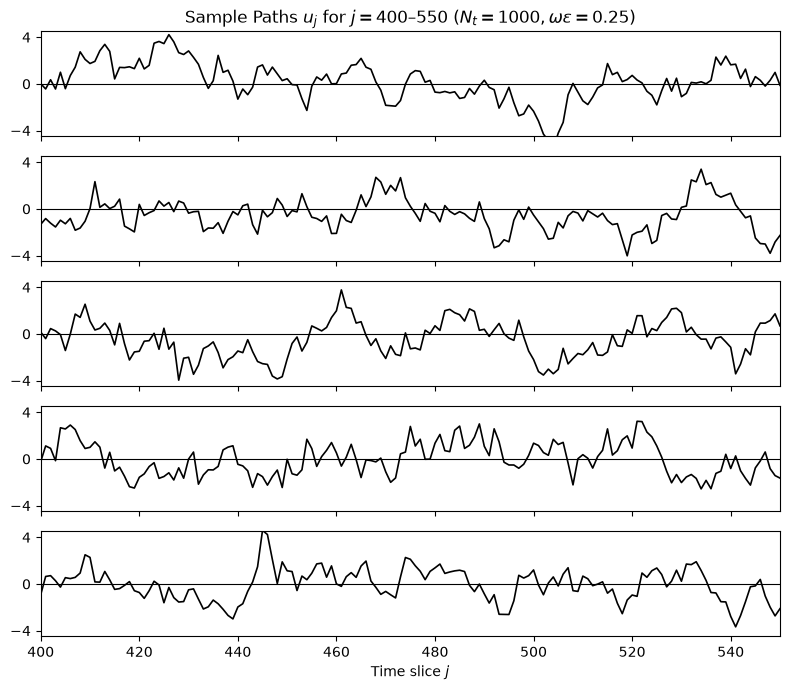

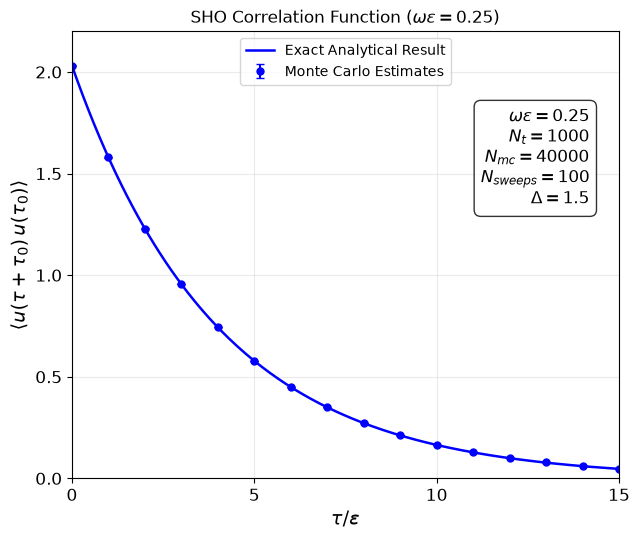

In [ ]:
# =====================================================================
# Reproducing Fig. 9 (Sample Paths) and Fig. 10 (Correlation Function)
# =====================================================================
Delta = 1.5
N_therm = 500
N_sweeps = 100    # Sweeps skipped between saved measurements
N_mc = 40000       # Number of decorrelated path measurements
max_tau = 15     # Evaluate <u(tau0 + tau) u(tau0)> for tau/eps = 0..15

# = np.ones(Nt + 1)  # hot start: u_j = 1 for all j
u = np.zeros(Nt + 1)  # cold start: u_j = 0 for all j

# 1. Thermalization Phase
for _ in range(N_therm):
    sweep_sequential(u, g, Delta, rng)

# 2. Measurement Phase
saved_paths = []
corr_samples = np.zeros((N_mc, max_tau + 1)) # Store <u(tau0 + tau) u(tau0)> for each decorrelated path. max_tau + 1 because we include tau=0.
i_start, i_end = 200, 800  # Bulk interior region away from ends u_0 = u_Nt = 0

for m in range(N_mc):
    # Skip N_sweeps between measurements to decorrelate paths
    for _ in range(N_sweeps):
        sweep_sequential(u, g, Delta, rng)
        
    # Save first 5 decorrelated paths for Fig. 9 (slices j = 400..550)
    if m < 5:
        saved_paths.append(u[400:551].copy())
        
    # Measure <u(tau0 + tau) u(tau0)>. Means averaging across the physical length of a single path. See mini example below. 
    u_base = u[i_start:i_end]
    for tau in range(max_tau + 1):
        corr_samples[m, tau] = np.mean(u_base * u[i_start + tau : i_end + tau])

# Compute Monte Carlo mean and standard error for each tau. It is like taking the ensemble average of the correlation function across all N_mc paths.
mc_corr_mean = np.mean(corr_samples, axis=0) # axis 0 means operating over rows, which gives result for each column (tau). From 400 paths to 1 path for each as a function of time slice tau.
mc_corr_err = np.std(corr_samples, axis=0, ddof=1) / np.sqrt(N_mc) # ddof=1 gives unbiased sample standard deviation

# Exact analytical lattice propagator
tau_vals = np.arange(0, max_tau + 1) # tau =  0, 1, 2,.. ,15
tau_fine = np.linspace(0, max_tau, 200)
sqrt_k = 0.5 * omega_eps
exact_curve = ((1.0 + kappa) / (4.0 * sqrt_k)) * ((1.0 - sqrt_k) / (1.0 + sqrt_k)) ** tau_fine

# =====================================================================
# Plot Fig. 9: 5 Sample Quantum Paths for j = 400 - 550
# =====================================================================
fig, axes = plt.subplots(5, 1, figsize=(8, 7), sharex=True)
j_slice = np.arange(400, 551)

for idx, ax in enumerate(axes): # enumerate gives both the index and the element from saved_paths
    ax.plot(j_slice, saved_paths[idx], 'k-', lw=1.2)
    ax.axhline(0.0, color='black', lw=0.8)
    ax.set_ylim(-4.5, 4.5)
    ax.set_yticks([-4, 0, 4])
    ax.set_xlim(400, 550)

axes[0].set_title(r'Sample Paths $u_j$ for $j = 400\text{–}550$ ($N_t = 1000, \omega\varepsilon = 0.25$)')
axes[-1].set_xlabel('Time slice $j$')
plt.tight_layout()
plt.show()

# =====================================================================
# Plot Fig. 10: Two-Point Correlation Function <u(tau0 + tau) u(tau0)>
# =====================================================================
plt.figure(figsize=(6.5, 5.5))
plt.plot(tau_fine, exact_curve, 'b-', lw=1.8, label='Exact Analytical Result')
plt.errorbar(tau_vals, mc_corr_mean, yerr=mc_corr_err, fmt='bo', markersize=5,
             capsize=3, label='Monte Carlo Estimates')

plt.xlim(0, 15)
plt.ylim(0, 2.2)
plt.xticks([0, 5, 10, 15], fontsize=12)
plt.yticks([0, 0.5, 1, 1.5, 2], fontsize=12)
plt.xlabel(r'$\tau / \varepsilon$', fontsize=14)
plt.ylabel(r'$\langle u(\tau + \tau_0)\, u(\tau_0) \rangle$', fontsize=14)
plt.title(r'SHO Correlation Function ($\omega\varepsilon = 0.25$)')

# Add parameter text box matching Fig. 10
info_text = (
    rf"$\omega\varepsilon = {omega_eps}$" + "\n" +
    rf"$N_t = {Nt}$" + "\n" +
    rf"$N_{{mc}} = {N_mc}$" + "\n" +
    rf"$N_{{sweeps}} = {N_sweeps}$" + "\n" +
    rf"$\Delta = {Delta}$"
)
plt.text(14.2, 1.35, info_text, fontsize=12, horizontalalignment='right',
         bbox=dict(boxstyle='round,pad=0.4', facecolor='white', alpha=0.8))

plt.legend(loc='upper center', fontsize=10)
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

**Questions**

1. How do we know that system is thermalized ? - Plot autocorrelation 
2. Do u understand difference between tau and lag (h) ? 

Ans - Physical Time ($\tau$) vs. Monte Carlo Time (Lag $h$ / $N_{\text{sweeps}}$)

* **Physical (Euclidean) Time ($\tau$):** Shifts across different time slices within a **single** quantum path array `u` (from slice $j$ to $j + \tau/\varepsilon$). It measures a physical property of the system: how strongly the particle's position at time $\tau_0$ correlates with its position at a later time $\tau_0 + \tau$ in the two-point correlation function $\langle u(\tau_0 + \tau) u(\tau_0) \rangle$.
* **Monte Carlo Simulation Time (Lag $h$ / $N_{\text{sweeps}}$):** Shifts across consecutive **Markov chain sweeps** (from Sweep $m$ to Sweep $m + h$). It measures an algorithmic property of the simulation: how many sweeps are required for the newly updated path configuration to decorrelate (forget) its previous state in the autocorrelation function $\rho(h)$.

3. How exactly we are finding the correlation functions ?
Ans - See mini version below :

In [ ]:
import numpy as np

# 3 snapshots or 3 decorrelated paths (N_mc = 3), each path has 7 slices (indices 0..6)
paths = np.array([
    [0, 1, 2, 3, 4, 5, 0],  # m = 0 (path 0)
    [0, 2, 2, 2, 2, 2, 0],  # m = 1 (path 1)
    [0, 1, 3, 1, 3, 1, 0]   # m = 2 (path 2)
])

N_m = len(paths)  # 3 rows
max_t = 2          # t = 0, 1, 2 (3 columns)
j_start = 1
j_end = 4          # Base window has 4 - 1 = 3 elements

# 2D array: 3 rows (m) x 3 columns (t)
samples = np.zeros((N_m, max_t + 1))

for m in range(N_m):
    u = paths[m]                 # Grab current path m
    u_base = u[j_start:j_end]    # Fixed window u[1:4]
    
    for t in range(max_t + 1):
        u_shifted = u[j_start + t : j_end + t]
        samples[m, t] = np.mean(u_base * u_shifted)
        print(u_base, u_shifted, samples[m, t])

print("2D samples table (rows = m, columns = t):")
print(samples)

# Final average down the rows (axis=0) for each column t
mc_corr_mean = np.mean(samples, axis=0)
print("\nFinal mean across snapshots (axis=0):", mc_corr_mean)

[1 2 3] [1 2 3] 4.666666666666667
[1 2 3] [2 3 4] 6.666666666666667
[1 2 3] [3 4 5] 8.666666666666666
[2 2 2] [2 2 2] 4.0
[2 2 2] [2 2 2] 4.0
[2 2 2] [2 2 2] 4.0
[1 3 1] [1 3 1] 3.6666666666666665
[1 3 1] [3 1 3] 3.0
[1 3 1] [1 3 1] 3.6666666666666665
2D samples table (rows = m, columns = t):
[[4.66666667 6.66666667 8.66666667]
 [4.         4.         4.        ]
 [3.66666667 3.         3.66666667]]

Final mean across snapshots (axis=0): [4.11111111 4.55555556 5.44444444]


4. How do we map Markov Chain Theory to the Simple Harmonic Oscillator ?

Ans - When applying stochastic process definitions ($X_n$) to a quantum path integral simulation, there is a crucial distinction between a single coordinate $u_j$ and a Markov state $X_n$:

* **Stochastic Time Index ($n$):** The index $n = 0, 1, 2, \dots$ is **Monte Carlo sweep time** (simulation steps), not physical Euclidean time $\tau$.
* **Markov State ($X_n = \mathbf{u}^{(n)}$):** A single state in the Markov chain is an **entire $(N_t - 1)$-dimensional particle path** at sweep $n$:
  $$X_n = \mathbf{u}^{(n)} = \big(u_1^{(n)}, u_2^{(n)}, \dots, u_{N_t-1}^{(n)}\big) \in \mathbb{R}^{N_t-1}$$
  * **At $n = 0$ (Cold Start):** The chain starts in the flat path state $X_0 = (0, 0, \dots, 0)$.
  * **At $n = 1, 2, \dots$ (Subsequent Sweeps):** Each sweep transitions the system from one entire 999-point path $\mathbf{u}^{(n)}$ to a new 999-point path $\mathbf{u}^{(n+1)}$.
* **Stationary Probability Vector ($w_i \to w(\mathbf{u})$):** Instead of a discrete vector over finite states, the invariant distribution is the normalized multidimensional Boltzmann probability density over all possible path configurations:
  $$w(\mathbf{u}) = \frac{1}{Z} e^{-S[\mathbf{u}]/\hbar}$$
* **Irreducibility in Path Space:** Because local updates shift each slice by $\delta \in [-\Delta, +\Delta]$, any path configuration $\mathbf{u}$ can deform into any other path configuration $\mathbf{u}'$ in a finite number of sweeps.
* **Aperiodicity in Path Space ($p_{ii} > 0$):** At each slice update (and across a full sweep), there is a non-zero probability that the Metropolis test (`rands[j] >= np.exp(-dS)`) rejects the proposed change, leaving the state unchanged ($X_{n+1} = X_n$). Having $p_{ii} > 0$ breaks any cyclic ping-pong behavior and guarantees aperiodicity ($d = 1$).
* **Positive Recurrence in Path Space ($\mu < \infty$):** The quadratic restoring terms $\sum u_j^2$ in the action $S[\mathbf{u}]$ and the fixed endpoints $u_0 = u_{N_t} = 0$ prevent the path coordinates from drifting off to $\pm\infty$. Instead, the Markov chain repeatedly returns to the high-probability region of path space (paths fluctuating within $\pm 4$ around zero) in a finite expected number of sweeps ($\mu < \infty$).

### Extracting the Ground State Wavefunction $|\psi_0(u)|^2$ and Energy $E_0$

In a Euclidean path integral simulation, we do not solve the Schrödinger differential equation directly. Instead, both the ground state probability density $|\psi_0(u)|^2$ and the ground state energy $E_0$ emerge statistically from the ensemble of thermalized paths and the two-point propagator $C(\tau)$.


#### Ground State Wavefunction $|\psi_0(u)|^2$ via Bulk Histogramming

##### Euclidean Time Projection onto the Ground State
Any quantum state created at the boundary $\tau = 0$ can be expanded in the energy eigenbasis $\{|n\rangle\}$ with eigenvalues $E_0 < E_1 < E_2 < \dots$. Under Euclidean time evolution $\hat{U}(\tau) = e^{-\hat{H}\tau/\hbar}$, every excited state $n \ge 1$ is exponentially suppressed relative to the ground state $|0\rangle$:

$$|\Psi(\tau)\rangle = \sum_{n=0}^{\infty} c_n e^{-E_n \tau / \hbar} |n\rangle = e^{-E_0 \tau / \hbar} \left( c_0 |0\rangle + c_1 e^{-(E_1 - E_0)\tau/\hbar}|1\rangle + \dots \right) \xrightarrow{\tau \to \infty} c_0 e^{-E_0 \tau / \hbar} |0\rangle$$

* **Why We Only Sample the Interior Bulk (`i_start = 200` to `i_end = 800`):** At the boundaries ($j = 0$ and $j = N_t$), the path is artificially pinned to $u_0 = u_{N_t} = 0$, which mixes in higher excited states. By moving $\ge 200$ slices away from both endpoints ($\tau = 200\varepsilon \implies \omega\tau = 50 \gg 1$), all excited state contributions ($e^{-50} \approx 10^{-22}$) have completely decayed away, leaving the system purely in its **ground state** $|0\rangle$.

##### Histogramming the Path Coordinates
In the interior bulk, the probability of finding a path slice $u_j$ inside a small interval $[u, u + du]$ is directly proportional to the ground state probability density $|\psi_0(u)|^2 du$.
* Across $N_{\text{mc}} = 40000$ decorrelated snapshots, we extract the $600$ interior slices `u_wf[200:800]` from each snapshot and flatten them into a single array `u_all` containing $40000 \times 600 = 24 \times 10^6$ position measurements.
* Plotting a normalized histogram (`density=True`) of `u_all` directly reconstructs $|\psi_0(u)|^2$.
* **Exact Analytical Comparison:** For the discretized quadratic action, the exact marginal distribution of any bulk coordinate $u_j$ is a Gaussian centered at $0$ with variance $\sigma_u^2 = \langle u^2 \rangle = C(0)$:

$$|\psi_0(u)|^2 = \frac{1}{\sqrt{2\pi \sigma_u^2}} \exp\left(-\frac{u^2}{2\sigma_u^2}\right), \qquad \text{where } \sigma_u^2 = \frac{1 + \kappa}{4\sqrt{\kappa}} = 2.03125$$

*(In the continuum limit $\varepsilon \to 0$, $\kappa \to 0$ and $\sqrt{\kappa} = \frac{1}{2}\omega\varepsilon$, which recovers $\sigma_u^2 = \frac{1}{2\omega\varepsilon} = 2.0$.)*


#### Ground State Energy $E_0$ (Two Independent Methods)

We extract the dimensionless ground state energy $\frac{E_0}{\hbar\omega}$ (exact continuum value $= 0.5$) using two complementary methods:

##### Method A: Via the Quantum Virial Theorem (From $\langle u^2 \rangle$)
For a harmonic potential $V(x) = \frac{1}{2}m\omega^2 x^2$, the quantum Virial Theorem states that the ground state expectation values of the kinetic and potential energies are equal ($\langle T \rangle = \langle V \rangle$). Therefore, the total ground state energy is twice the average potential energy:

$$E_0 = \langle T \rangle + \langle V \rangle = 2\langle V \rangle = 2 \left(\frac{1}{2} m\omega^2 \langle x^2 \rangle\right) = m\omega^2 \langle x^2 \rangle$$

* **Converting to Dimensionless Lattice Coordinates $u$:**
  Recall our non-dimensionalization definitions:
  $$d_j = x_j \sqrt{\frac{m}{\hbar\varepsilon}}, \qquad u_j = d_j \sqrt{1 + \kappa} \quad \Longrightarrow \quad x_j^2 = \frac{\hbar\varepsilon}{m(1 + \kappa)} u_j^2 \approx \frac{\hbar\varepsilon}{m} u_j^2$$
  Substituting $x^2$ into the Virial Theorem and dividing by $\hbar\omega$ gives the continuum estimator:

$$\frac{E_0}{\hbar\omega} = \omega\varepsilon \, \langle u^2 \rangle$$

  *(Or, keeping the finite lattice spacing factor $(1+\kappa)$ from the rescaling, $\frac{E_0}{\hbar\omega} = \omega\varepsilon(1+\kappa)\langle u^2 \rangle$.)*
* **In the Code:** We compute `u2_mean = np.mean(u_all**2)` across all bulk measurements and multiply by `omega_eps = 0.25`. To get a true, unbiased statistical error bar `E0_virial_err`, we first average $u^2$ within each individual path (`axis=1`) so we have $N_{\text{mc}} = 40000$ independent path averages, and then compute the standard error of the mean across those $40000$ snapshots (`/ np.sqrt(N_mc)`).


##### Method B: Via the Spectral Decomposition of the Propagator $C(\tau)$ (Effective Mass Plateau)
In general Lattice QCD problems, potentials are not simple quadratics and the Virial Theorem cannot be used. The universal method to extract energies on a lattice is from the exponential decay rate of the two-point correlation function $C(\tau) = \langle u(\tau_0 + \tau) u(\tau_0) \rangle$.

* **Spectral Decomposition (Inserting a Complete Set of States $\sum_n |n\rangle\langle n| = \mathbf{I}$):**
  Writing the Heisenberg operators in Euclidean time as $\hat{u}(\tau) = e^{\hat{H}\tau/\hbar} \hat{u} e^{-\hat{H}\tau/\hbar}$ and taking the expectation value in the ground state $|0\rangle$ gives:

$$C(\tau) = \langle 0 | \hat{u}(\tau) \hat{u}(0) | 0 \rangle = \sum_{n=1}^{\infty} |\langle 0 | \hat{u} | n \rangle|^2 \, e^{-(E_n - E_0)\tau/\hbar}$$

* **Single-State Dominance:** For the harmonic oscillator, the position operator $\hat{u} \propto (\hat{a} + \hat{a}^\dagger)$ only connects the ground state $|0\rangle$ to the first excited state $|1\rangle$ ($\langle 0 | \hat{u} | n \rangle = 0$ for all $n \ne 1$). Thus, even at small $\tau$, the correlator is a single pure exponential governed by the first energy gap $\Delta E_1 = E_1 - E_0$:

$$C(\tau) = |\langle 0 | \hat{u} | 1 \rangle|^2 \, e^{-(E_1 - E_0)\tau/\hbar}$$

* **The Log-Ratio (Effective Energy Gap):** Taking the ratio of the correlator at two consecutive time steps $\tau$ and $\tau + \varepsilon$ cancels the unknown matrix element prefactor $|\langle 0 | \hat{u} | 1 \rangle|^2$:

$$\frac{C(\tau)}{C(\tau + \varepsilon)} = \exp\left( \frac{(E_1 - E_0)\varepsilon}{\hbar} \right) \quad \Longrightarrow \quad \frac{\Delta E_{\text{eff}}(\tau)}{\hbar\omega} = \frac{1}{\omega\varepsilon} \ln\left( \frac{C(\tau)}{C(\tau + \varepsilon)} \right)$$

  Because $E_n = \hbar\omega(n + \frac{1}{2})$ for the harmonic oscillator, the energy gap is $\Delta E_1 = E_1 - E_0 = \hbar\omega$, and the ground state energy is exactly half the gap:

$$\frac{E_0(\tau)}{\hbar\omega} = \frac{1}{2} \frac{\Delta E_{\text{eff}}(\tau)}{\hbar\omega} = \frac{1}{2\omega\varepsilon} \ln\left( \frac{C(\tau)}{C(\tau + \varepsilon)} \right)$$

* **In the Code (`mc_corr_mean[:-1] / mc_corr_mean[1:]`):**
  * `mc_corr_mean[:-1]` slices $[C(0), C(1), \dots, C(14)]$ and `mc_corr_mean[1:]` slices $[C(1), C(2), \dots, C(15)]$.
  * Dividing them element-wise and taking `np.log(...)` produces the **Effective Energy Plateau** plotted in the right panel.

Ground State Energy E_0 / (hbar*omega) [Exact Continuum = 0.5000]:
  -> From Virial Theorem (<u^2>):   0.5077 +/- 0.0003
  -> From Propagator Log-Ratio:     0.5028


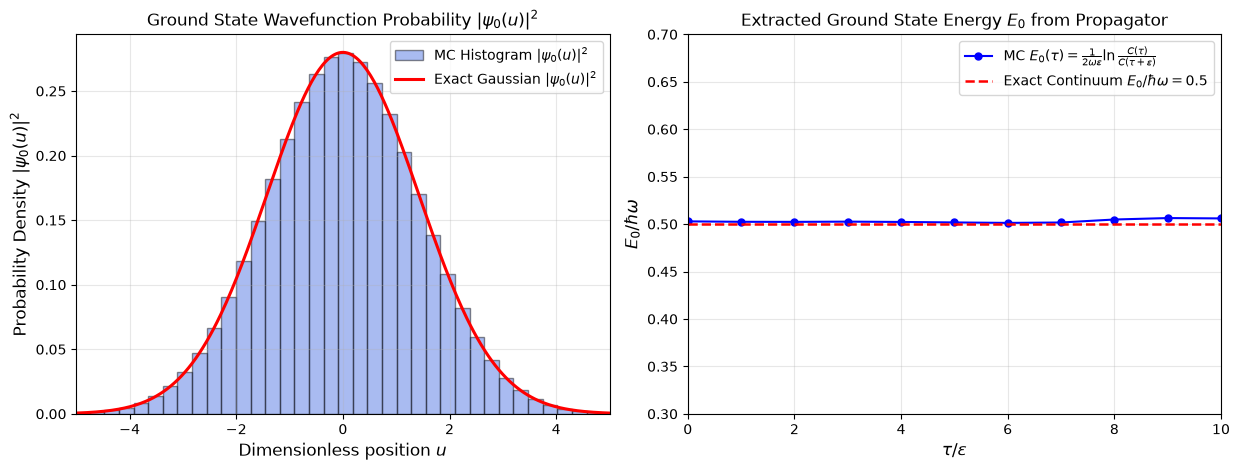

In [ ]:
# =====================================================================
# Extracting Ground State Wavefunction |psi_0(u)|^2 and Ground State Energy E_0
# =====================================================================

# 1. Collect bulk path values u_j across decorrelated sweeps for the wavefunction
u_samples = []
u_wf = np.zeros(Nt + 1)

# Thermalize
for _ in range(N_therm):
    sweep_sequential(u_wf, g, Delta, rng)

# Measure interior u_j values and correlator simultaneously
corr_samples_wf = np.zeros((N_mc, max_tau + 1))


for m in range(N_mc):
    for _ in range(N_sweeps):
        sweep_sequential(u_wf, g, Delta, rng)
        
    u_base = u_wf[i_start:i_end]
    u_samples.append(u_base.copy())  # Store 600 interior slices per snapshot
    
    for tau in range(max_tau + 1):
        corr_samples_wf[m, tau] = np.mean(u_base * u_wf[i_start + tau : i_end + tau])

u_all = np.concatenate(u_samples)  # 40000 * 600 = 24,000,000 position measurements!
mc_corr_mean = np.mean(corr_samples_wf, axis=0) # Compute <u(tau0 + tau) u(tau0)> averaged over all N_mc paths at each tau.

# =====================================================================
# 2. Compute Ground State Energy E_0 (in units of hbar * omega)
# =====================================================================
# Method A: Virial Theorem E_0 / (hbar * omega) = omega_eps * <u^2>
u2_mean = np.mean(u_all**2)
u2_err = np.std(np.mean(np.array(u_samples)**2, axis=1), ddof=1) / np.sqrt(N_mc) # Standard error of the mean <u^2> across N_mc paths

E0_virial = omega_eps * u2_mean
E0_virial_err = omega_eps * u2_err

# Method B: Effective Energy Gap from Propagator Ratio ln(C(tau) / C(tau+1))
# For SHO, dE = E_1 - E_0 = hbar*omega, and E_0 = 0.5 * dE
eff_gap = (1.0 / omega_eps) * np.log(mc_corr_mean[:-1] / mc_corr_mean[1:])
E0_from_prop = 0.5 * eff_gap[0]  # Using tau=0 -> tau=1 step (highest signal-to-noise)

print(f"Ground State Energy E_0 / (hbar*omega) [Exact Continuum = 0.5000]:")
print(f"  -> From Virial Theorem (<u^2>):   {E0_virial:.4f} +/- {E0_virial_err:.4f}")
print(f"  -> From Propagator Log-Ratio:     {E0_from_prop:.4f}")

# =====================================================================
# 3. Plot Ground State Wavefunction |psi_0(u)|^2 & Effective Energy Plateau
# =====================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.8))

# Left Panel: Ground State Probability Density |psi_0(u)|^2 and Wavefunction psi_0(u)
counts, bin_edges, _ = ax1.hist(
    u_all, bins=60, density=True, alpha=0.45, color='royalblue',
    edgecolor='black', label=r'MC Histogram $|\psi_0(u)|^2$'
)
u_grid = np.linspace(-5, 5, 300)
sigma2_exact = (1.0 + kappa) / (4.0 * 0.5 * omega_eps)  # Exact lattice variance = 2.03125
psi0_sq_exact = (1.0 / np.sqrt(2.0 * np.pi * sigma2_exact)) * np.exp(-u_grid**2 / (2.0 * sigma2_exact))

ax1.plot(u_grid, psi0_sq_exact, 'r-', lw=2.2, label=r'Exact Gaussian $|\psi_0(u)|^2$')
ax1.set_xlim(-5, 5)
ax1.set_xlabel(r'Dimensionless position $u$', fontsize=12)
ax1.set_ylabel(r'Probability Density $|\psi_0(u)|^2$', fontsize=12)
ax1.set_title(r'Ground State Wavefunction Probability $|\psi_0(u)|^2$')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Right Panel: Effective Ground State Energy E_0 = 0.5 * dE_eff(tau) vs tau/eps
tau_steps = np.arange(len(eff_gap))
ax2.plot(tau_steps, 0.5 * eff_gap, 'bo-', markersize=5, label=r'MC $E_0(\tau) = \frac{1}{2\omega\varepsilon}\ln\frac{C(\tau)}{C(\tau+\varepsilon)}$')
ax2.axhline(0.5, color='r', ls='--', lw=1.8, label=r'Exact Continuum $E_0 / \hbar\omega = 0.5$')
ax2.set_xlim(0, 10)
ax2.set_ylim(0.3, 0.7)
ax2.set_xlabel(r'$\tau / \varepsilon$', fontsize=12)
ax2.set_ylabel(r'$E_0 / \hbar\omega$', fontsize=12)
ax2.set_title(r'Extracted Ground State Energy $E_0$ from Propagator')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()